In [27]:
from preprocessing import preprocessing
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [28]:
df = pd.read_csv("/home/victor/code/Victorpeereiraa/cross_genre_music_discovery/raw_data/spotify-tracks-dataset-detailed.csv")

In [29]:
X_scaled, df_metadata, scaler,features = preprocessing(df)

In [30]:
X_scaled

array([[ 0.64297552, -0.67154365,  0.33150122, ..., -0.53930511,
         0.93165132, -1.14395948],
       [-0.80082937, -1.81855779, -1.67694106, ..., -0.53929111,
        -0.76950845, -1.4909656 ],
       [-0.69931184, -1.06813837, -0.24064346, ..., -0.53930821,
        -1.32770149, -1.52946638],
       ...,
       [ 0.37790197, -1.18478387, -0.46295269, ..., -0.53930821,
         1.0379738 ,  0.33554178],
       [ 0.14102773, -0.49657539, -0.4618038 , ..., -0.53930821,
        -0.21511263,  0.45473778],
       [-0.20300391, -0.57045087, -0.33063944, ..., -0.53930821,
         0.90507069, -1.43409627]], shape=(88751, 8))

In [31]:
df_metadata

,track_id,artists,track_name,genres
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,"[acoustic, j-pop, singer-songwriter, songwriter]"
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost - Acoustic,"[acoustic, chill]"
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,[acoustic]
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Can't Help Falling In Love,[acoustic]
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,[acoustic]
...,...,...,...,...
88746,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,Sleep My Little Boy,[world-music]
88747,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,Water Into Light,[world-music]
88748,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Miss Perfumado,[world-music]
88749,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Friends,[world-music]


In [32]:
pca = PCA()
pca.fit(X_scaled)

,n_components,None
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


In [33]:
features

['danceability',
 'energy',
 'loudness',
 'speechiness',
 'acousticness',
 'instrumentalness',
 'valence',
 'tempo']

In [34]:
components = pca.components_

In [35]:
len(components)

8

In [36]:
components = pd.DataFrame(components.T,
                          index = features,
                          columns=[f'PC{i}' for i in range(1, 9)])

In [37]:
components

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
danceability,0.264796,0.534783,0.135961,-0.251591,0.397982,-0.605012,0.077189,0.178101
energy,0.498399,-0.297498,-0.051374,-0.170682,0.018022,0.263466,0.178191,0.727895
loudness,0.509835,-0.091840,-0.162907,-0.032740,-0.198980,-0.086291,0.620472,-0.521535
speechiness,0.153702,0.050686,0.935824,-0.011813,-0.280083,0.125619,0.003059,-0.060530
acousticness,-0.435959,0.354280,0.031666,0.311577,-0.087832,0.120567,0.684270,0.309623
instrumentalness,-0.278770,-0.346910,0.219328,-0.380029,0.666662,0.200411,0.299757,-0.186968
valence,0.297919,0.538606,-0.084650,0.120917,0.311481,0.671896,-0.137759,-0.178661
tempo,0.203462,-0.280252,0.142465,0.806372,0.417221,-0.187551,-0.015433,0.006617


In [38]:
X_proj = pca.transform(X_scaled)
X_proj = pd.DataFrame(X_proj, columns=[f'PC{i}' for i in range(1, 9)])
X_proj

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
0,0.694357,1.254424,0.393031,-0.941709,-0.506020,0.129137,-0.727019,-0.934638
1,-3.139431,1.086433,0.007441,0.032252,-1.383306,0.013971,-0.239554,0.191188
2,-1.294223,-0.268110,-0.509493,-0.924660,-1.549196,-0.628411,-0.581019,-0.535574
3,-3.184718,-0.502834,0.030796,3.057900,-0.246546,-0.582845,-0.561090,-0.017996
4,-0.850054,0.136656,-0.208913,0.195911,-0.537228,-1.221697,0.041052,0.095808
...,...,...,...,...,...,...,...,...
88746,-3.720461,-1.995120,0.296020,0.185000,0.522776,0.438122,0.174553,-0.547766
88747,-4.912135,-1.116462,0.229542,-0.548814,0.040990,0.752542,0.648861,-0.397765
88748,-0.972261,1.797437,-0.348436,1.231331,0.311601,0.162474,0.323321,-0.108870
88749,-0.434076,0.238729,-0.477846,0.670078,0.057296,-0.569967,-0.388892,0.136066


In [39]:
pca.explained_variance_ratio_

array([0.36562704, 0.17533674, 0.12175941, 0.11256348, 0.10492546,
       0.06123221, 0.04065637, 0.01789928])

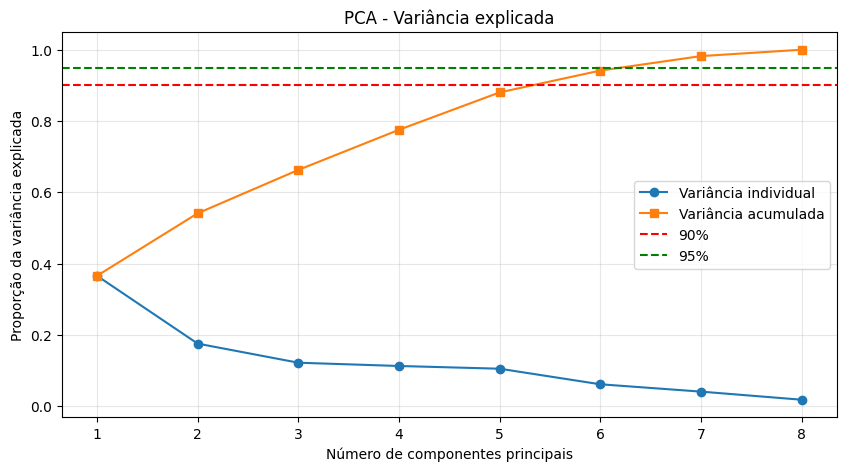

In [ ]:
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker='o',
    label='Variância individual'
)

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='s',
    label='Variância acumulada'
)

plt.axhline(0.90, color='red', linestyle='--', label='90%')
plt.axhline(0.95, color='green', linestyle='--', label='95%')

plt.xticks(range(1, 9))
plt.xlabel('Número de componentes principais')
plt.ylabel('Proporção da variância explicada')
plt.title('PCA - Variância explicada')
plt.legend()
plt.grid(alpha=0.3)
plt.show()
# Vendo o gráfico abaixo devemos testar os modelos com pca com 3,4 e 5

In [41]:
pca3 = PCA(n_components=3)

In [42]:
X_proj3 = pd.DataFrame(pca3.fit_transform(X_scaled), columns=['PC1', 'PC2', 'PC3'])

In [43]:
X_proj3

,PC1,PC2,PC3
0,0.694357,1.254424,0.393031
1,-3.139431,1.086433,0.007441
2,-1.294223,-0.268110,-0.509493
3,-3.184718,-0.502834,0.030796
4,-0.850054,0.136656,-0.208913
...,...,...,...
88746,-3.720461,-1.995120,0.296020
88747,-4.912135,-1.116462,0.229542
88748,-0.972261,1.797437,-0.348436
88749,-0.434076,0.238729,-0.477846
